# Clasificación de riesgo crediticio con una red neuronal y PCA

Este cuaderno entrena el modelo que usa la app [CreditScore](https://credit-score-app-v2-twqrfn7cwczj2wy7brujyf.streamlit.app/). A partir del perfil financiero de un cliente, el modelo lo clasifica en una de tres categorías de puntaje crediticio:

- **0, Bad:** riesgo alto
- **1, Standard:** riesgo medio
- **2, Good:** riesgo bajo

El flujo es: limpieza de datos, codificación de variables categóricas, división en entrenamiento y prueba, selección de variables, normalización, reducción de dimensionalidad con PCA, red neuronal y evaluación. Al final se guardan los cuatro archivos que carga la app.

**Regla que sigue todo el cuaderno:** cada transformación (selección de variables, escalado y PCA) se ajusta solo con los datos de entrenamiento. Así el conjunto de prueba se mantiene como datos que el modelo nunca vio y las métricas finales son honestas.

El cuaderno corre de principio a fin tanto en Google Colab como en local.

## 1. Librerías y semillas

Se fijan las semillas aleatorias para que el resultado sea reproducible.

In [1]:
import random
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.tree import DecisionTreeClassifier, export_text
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.random.set_seed(SEMILLA)

# Carpeta donde se guardan los archivos que usa la app (la raíz del repositorio)
SALIDA = Path("..") if Path("../app.py").exists() else Path(".")
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Carga de datos

El dataset `riesgo.xlsx` lo publica el profesor del curso en GitHub. Tiene 12.500 clientes; cada fila resume el comportamiento de un cliente durante varios meses, por eso algunas variables de conteo tienen decimales (son promedios).

In [2]:
URL_DATOS = "https://github.com/adiacla/bigdata/raw/master/riesgo.xlsx"
df = pd.read_excel(URL_DATOS)
print(df.shape)
# Se omiten nombre y documento al mostrar la tabla
df.drop(columns=["Name", "SSN"]).head()

(12500, 26)


,Customer_ID,Age,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,...,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,CUS_0x1000,17.375,Lawyer,30625.94,2706.161667,6.0,5.0,27,2,"Credit-Builder Loan, and Home Equity Loan",...,Bad,1562.91,25.036185,10.458333,Yes,81.797271,158.549735,High_spent_Medium_value_payments,335.375341,0
1,CUS_0x1009,25.750,Mechanic,52312.68,4250.390000,6.0,5.0,17,4,"Not Specified, Home Equity Loan, Credit-Builde...",...,Standard,202.68,50.771467,30.714286,Yes,53.546010,146.679378,High_spent_Medium_value_payments,428.743155,1
2,CUS_0x100b,18.500,Media_Manager,113781.39,9549.782500,1.0,4.0,1,0,NaN,...,Good,1030.20,29.610420,15.571429,No,83.438236,505.386526,High_spent_Large_value_payments,781.229776,0
3,CUS_0x1011,43.875,Doctor,58918.47,5208.872500,3.0,3.0,17,3,"Student Loan, Credit-Builder Loan, and Debt Co...",...,Standard,473.14,43.950325,15.541667,Yes,56.104813,311.060914,Low_spent_Medium_value_payments,332.642837,1
4,CUS_0x1013,43.750,Mechanic,98620.98,7962.415000,3.0,3.0,6,3,"Student Loan, Debt Consolidation Loan, and Per...",...,Good,1233.51,44.397384,17.535714,No,50.146076,355.442408,High_spent_Medium_value_payments,472.781009,1


In [3]:
NOMBRES_CLASE = ["Bad (0)", "Standard (1)", "Good (2)"]
conteo = df["Credit_Score"].value_counts().sort_index()
print(pd.DataFrame({"clase": NOMBRES_CLASE, "clientes": conteo.values, "porcentaje": (conteo / len(df) * 100).round(1).values}))

          clase  clientes  porcentaje
0       Bad (0)      4162        33.3
1  Standard (1)      6111        48.9
2      Good (2)      2227        17.8


Las clases están desbalanceadas: casi la mitad de los clientes son Standard y solo el 18% son Good. Por eso la división en entrenamiento y prueba se hace estratificada.

## 3. Limpieza

Se eliminan columnas que no deben entrar al modelo:

- `Customer_ID`, `Name` y `SSN` identifican a la persona y no describen su comportamiento financiero. Usarlas sería memorizar clientes.
- `Type_of_Loan` es un texto libre con combinaciones de préstamos, difícil de codificar sin crear cientos de columnas.
- `Occupation` tiene 15 categorías sin orden natural; se deja por fuera para mantener el modelo simple.

In [4]:
df = df.drop(columns=["Customer_ID", "Name", "SSN", "Type_of_Loan", "Occupation"])
df = df.dropna().reset_index(drop=True)
print(df.shape)
df.describe().T.round(2)

(12500, 21)


,count,mean,std,min,25%,50%,75%,max
Age,12500.0,33.31,10.76,14.00,24.42,33.00,41.75,56.00
Annual_Income,12500.0,50505.12,38300.76,7005.93,19342.97,36999.70,71683.47,179987.28
Monthly_Inhand_Salary,12500.0,4198.47,3187.14,303.65,1625.74,3097.02,5961.66,15204.63
Num_Bank_Accounts,12500.0,5.37,2.59,0.00,3.00,5.38,7.00,10.50
Num_Credit_Card,12500.0,5.53,2.07,0.50,4.00,5.00,7.00,10.88
Interest_Rate,12500.0,14.53,8.74,1.00,7.00,13.00,20.00,34.00
Num_of_Loan,12500.0,3.53,2.45,0.00,2.00,3.00,5.00,9.00
Delay_from_due_date,12500.0,21.07,14.77,-2.00,9.88,17.88,28.00,63.25
Num_of_Delayed_Payment,12500.0,13.34,6.15,0.00,9.00,13.75,18.18,26.38
Changed_Credit_Limit,12500.0,10.47,6.45,0.50,5.49,9.37,14.66,31.12


## 4. Codificación de variables categóricas

`Credit_Mix`, `Payment_of_Min_Amount` y `Payment_Behaviour` son texto. Se convierten a números con `LabelEncoder`. Los codificadores se guardan porque la app los necesita para transformar lo que escribe el usuario. Como las categorías son un conjunto cerrado y conocido, codificarlas antes de dividir los datos no filtra información del conjunto de prueba.

In [5]:
COLUMNAS_TEXTO = df.select_dtypes(include="object").columns.tolist()
label_encoders = {}
for columna in COLUMNAS_TEXTO:
    codificador = LabelEncoder()
    df[columna] = codificador.fit_transform(df[columna].astype(str))
    label_encoders[columna] = codificador
    print(columna, dict(zip(codificador.classes_, codificador.transform(codificador.classes_))))

Credit_Mix {'Bad': np.int64(0), 'Good': np.int64(1), 'Standard': np.int64(2)}
Payment_of_Min_Amount {'NM': np.int64(0), 'No': np.int64(1), 'Yes': np.int64(2)}
Payment_Behaviour {'High_spent_Large_value_payments': np.int64(0), 'High_spent_Medium_value_payments': np.int64(1), 'High_spent_Small_value_payments': np.int64(2), 'Low_spent_Large_value_payments': np.int64(3), 'Low_spent_Medium_value_payments': np.int64(4), 'Low_spent_Small_value_payments': np.int64(5)}


## 5. División en entrenamiento y prueba

Se separa el 15% de los clientes para la evaluación final, de forma estratificada para conservar la proporción de cada clase.

In [6]:
X = df.drop(columns=["Credit_Score"])
y = df["Credit_Score"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.15, random_state=SEMILLA, stratify=y
)
print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)

Entrenamiento: (10625, 20)  Prueba: (1875, 20)


## 6. Selección de las 15 variables más relevantes

`SelectKBest` con la prueba F de ANOVA ordena las variables según qué tanto cambia su promedio entre las tres clases. Se ajusta solo con entrenamiento.

In [7]:
selector = SelectKBest(score_func=f_classif, k=15)
selector.fit(X_train, y_train)
puntajes = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
VARIABLES = X.columns[selector.get_support()].tolist()
print(puntajes.round(1).to_string())
print("\nSeleccionadas:", VARIABLES)

Credit_Utilization_Ratio    24370.3
Total_EMI_per_month         18240.5
Interest_Rate                2132.9
Num_Credit_Inquiries         1847.5
Payment_of_Min_Amount        1791.2
Delay_from_due_date          1621.2
Num_Credit_Card              1333.1
Num_Bank_Accounts            1280.7
Num_of_Delayed_Payment       1251.5
Outstanding_Debt             1235.5
Credit_History_Age           1202.2
Credit_Mix                   1037.5
Num_of_Loan                   992.9
Monthly_Balance               511.2
Changed_Credit_Limit          437.6
Annual_Income                 293.0
Monthly_Inhand_Salary         288.2
Amount_invested_monthly       245.0
Age                           182.2
Payment_Behaviour             105.8

Seleccionadas: ['Num_Bank_Accounts', 'Num_Credit_Card', 'Interest_Rate', 'Num_of_Loan', 'Delay_from_due_date', 'Num_of_Delayed_Payment', 'Changed_Credit_Limit', 'Num_Credit_Inquiries', 'Credit_Mix', 'Outstanding_Debt', 'Credit_Utilization_Ratio', 'Credit_History_Age', 'Payment_o

In [8]:
MAPA_COLUMNAS = {
    "Num_Bank_Accounts": "Num_Cuentas_Bancarias",
    "Num_Credit_Card": "Num_Tarjetas_Credito",
    "Interest_Rate": "Tasa_Interes",
    "Num_of_Loan": "Num_Prestamos",
    "Delay_from_due_date": "Retraso_Desde_Vencimiento",
    "Num_of_Delayed_Payment": "Num_Pagos_Retrasados",
    "Changed_Credit_Limit": "Cambio_Limite_Credito",
    "Num_Credit_Inquiries": "Num_Consultas_Credito",
    "Credit_Mix": "Mezcla_Credito",
    "Outstanding_Debt": "Deuda_Pendiente",
    "Credit_Utilization_Ratio": "Ratio_Utilizacion_Credito",
    "Credit_History_Age": "Antiguedad_Historial_Crediticio",
    "Payment_of_Min_Amount": "Pago_Monto_Minimo",
    "Total_EMI_per_month": "Cuota_Mensual_Total",
    "Monthly_Balance": "Balance_Mensual",
}
# La app espera exactamente estas 15 variables en este orden
assert VARIABLES == list(MAPA_COLUMNAS), "La selección cambió: hay que actualizar la app"

X_train_sel = X_train[VARIABLES].rename(columns=MAPA_COLUMNAS)
X_test_sel = X_test[VARIABLES].rename(columns=MAPA_COLUMNAS)
X_train_sel.describe().T[["min", "mean", "max"]].round(2)

,min,mean,max
Num_Cuentas_Bancarias,0.00,5.38,10.50
Num_Tarjetas_Credito,0.50,5.53,10.88
Tasa_Interes,1.00,14.55,34.00
Num_Prestamos,0.00,3.55,9.00
Retraso_Desde_Vencimiento,-1.88,21.16,63.25
Num_Pagos_Retrasados,0.00,13.37,26.38
Cambio_Limite_Credito,0.50,10.54,30.98
Num_Consultas_Credito,0.00,5.79,16.38
Mezcla_Credito,0.00,1.22,2.00
Deuda_Pendiente,0.34,1428.85,4997.10


Los mínimos y máximos de esta tabla son los que la app usa como límites de cada campo, para no pedirle al modelo predicciones fuera del rango que conoce.

## 7. Normalización y PCA

Las variables tienen escalas muy distintas (la deuda llega a 5.000 y el número de préstamos a 9), así que se llevan al rango 0 a 1 con `MinMaxScaler`. Después, PCA resume las 15 variables en 8 componentes.

In [9]:
scaler = MinMaxScaler()
X_train_norm = scaler.fit_transform(X_train_sel)
X_test_norm = scaler.transform(X_test_sel)

pca = PCA(n_components=8, random_state=SEMILLA)
X_train_pca = pca.fit_transform(X_train_norm)
X_test_pca = pca.transform(X_test_norm)

varianza = pd.DataFrame({
    "componente": [f"PC{i+1}" for i in range(8)],
    "varianza": pca.explained_variance_ratio_.round(3),
    "acumulada": pca.explained_variance_ratio_.cumsum().round(3),
})
print(varianza.to_string(index=False))

componente  varianza  acumulada
       PC1     0.487      0.487
       PC2     0.158      0.645
       PC3     0.058      0.703
       PC4     0.046      0.749
       PC5     0.036      0.785
       PC6     0.030      0.814
       PC7     0.029      0.843
       PC8     0.027      0.870


Con 8 componentes se conserva cerca del 87% de la varianza de las 15 variables originales.

## 8. Red neuronal

Red densa pequeña con tres capas ocultas y salida softmax de tres clases. Se reserva el 15% del entrenamiento como validación y se usa *early stopping*: el entrenamiento se detiene cuando la pérdida de validación deja de mejorar durante 8 épocas, y se recuperan los mejores pesos.

In [10]:
y_train_cat = to_categorical(y_train, num_classes=3)
y_test_cat = to_categorical(y_test, num_classes=3)

modelo = Sequential([
    Input(shape=(8,)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(3, activation="softmax"),
])
modelo.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,235 (12.64 KB)

 Trainable params: 3,235 (12.64 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
parada = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
historial = modelo.fit(
    X_train_pca, y_train_cat,
    epochs=100, batch_size=32, validation_split=0.15,
    callbacks=[parada], verbose=0,
)
print("Épocas entrenadas:", len(historial.history["loss"]))

Épocas entrenadas: 11


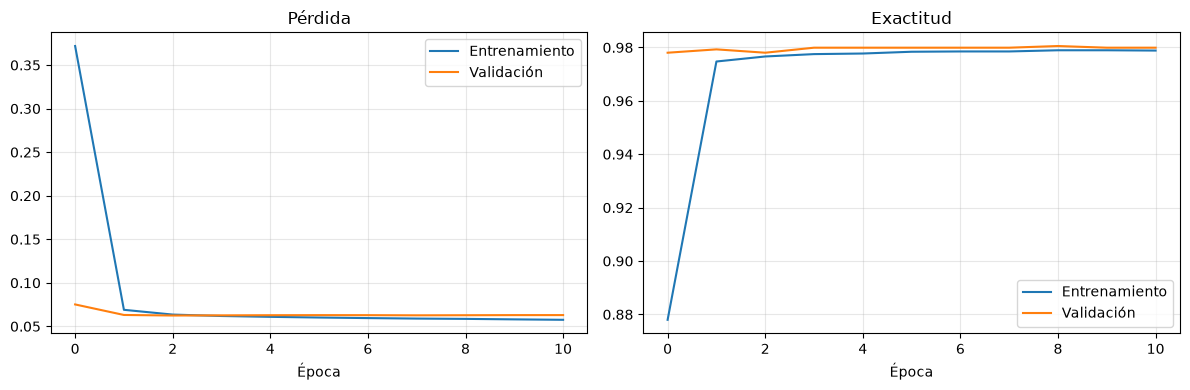

In [12]:
hist = pd.DataFrame(historial.history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist["loss"], label="Entrenamiento")
ax[0].plot(hist["val_loss"], label="Validación")
ax[0].set_title("Pérdida")
ax[1].plot(hist["accuracy"], label="Entrenamiento")
ax[1].plot(hist["val_accuracy"], label="Validación")
ax[1].set_title("Exactitud")
for eje in ax:
    eje.set_xlabel("Época")
    eje.legend()
    eje.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Evaluación en el conjunto de prueba

In [13]:
probabilidades = modelo.predict(X_test_pca, verbose=0)
y_pred = probabilidades.argmax(axis=1)
exactitud_red = accuracy_score(y_test, y_pred)
print(f"Exactitud en prueba: {exactitud_red:.4f}\n")
print(classification_report(y_test, y_pred, target_names=NOMBRES_CLASE, digits=3))

Exactitud en prueba: 0.9808

              precision    recall  f1-score   support

     Bad (0)      0.984     0.987     0.986       624
Standard (1)      0.980     0.980     0.980       917
    Good (2)      0.976     0.970     0.973       334

    accuracy                          0.981      1875
   macro avg      0.980     0.979     0.980      1875
weighted avg      0.981     0.981     0.981      1875



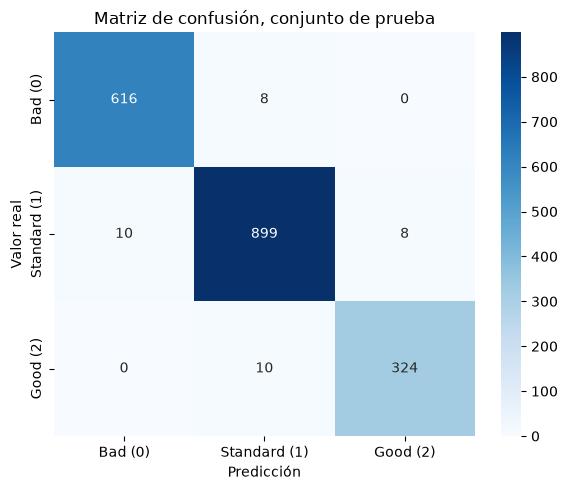

In [14]:
matriz = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", xticklabels=NOMBRES_CLASE, yticklabels=NOMBRES_CLASE, ax=ax)
ax.set_xlabel("Predicción")
ax.set_ylabel("Valor real")
ax.set_title("Matriz de confusión, conjunto de prueba")
plt.tight_layout()
plt.show()

## 10. ¿La red neuronal hace falta? Comparación con modelos simples

Una exactitud cercana al 97% es muy alta para un problema de riesgo crediticio. Antes de atribuirle el mérito a la red, conviene compararla con modelos más simples entrenados con los mismos datos de entrenamiento.

In [15]:
comparacion = {"Red neuronal + PCA (8 componentes)": exactitud_red}

logistica = LogisticRegression(max_iter=2000).fit(X_train_norm, y_train)
comparacion["Regresión logística (15 variables)"] = accuracy_score(y_test, logistica.predict(X_test_norm))

for profundidad in [2, 5]:
    arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=SEMILLA).fit(X_train_sel, y_train)
    comparacion[f"Árbol de decisión, profundidad {profundidad}"] = accuracy_score(y_test, arbol.predict(X_test_sel))

pd.Series(comparacion, name="exactitud en prueba").round(4).to_frame()

,exactitud en prueba
Red neuronal + PCA (8 componentes),0.9808
Regresión logística (15 variables),0.9872
"Árbol de decisión, profundidad 2",0.9717
"Árbol de decisión, profundidad 5",0.9861


In [16]:
arbol_simple = DecisionTreeClassifier(max_depth=2, random_state=SEMILLA).fit(X_train_sel, y_train)
print(export_text(arbol_simple, feature_names=list(X_train_sel.columns), class_names=NOMBRES_CLASE))

|--- Ratio_Utilizacion_Credito <= 30.79
|   |--- Cuota_Mensual_Total <= 52.23
|   |   |--- class: Bad (0)
|   |--- Cuota_Mensual_Total >  52.23
|   |   |--- class: Bad (0)
|--- Ratio_Utilizacion_Credito >  30.79
|   |--- Cuota_Mensual_Total <= 30.50
|   |   |--- class: Good (2)
|   |--- Cuota_Mensual_Total >  30.50
|   |   |--- class: Standard (1)



El resultado cambia la lectura del proyecto: una regresión logística y un árbol de decisión de profundidad 5 igualan o superan a la red, y un árbol de profundidad 2, que solo mira la utilización del crédito y la cuota mensual, se queda a un punto de ella. Las reglas del árbol además no tienen sentido financiero: clasifica como riesgo alto a todo el que usa menos del 31% de su crédito.

Eso indica que en este dataset la etiqueta se explica casi por completo con un par de umbrales, probablemente porque fue construida o ajustada para un ejercicio de clase. La red neuronal funciona bien, pero no porque haya aprendido algo difícil. Con datos reales de un banco no se debe esperar este desempeño.

## 11. Guardar los archivos que usa la app

In [17]:
modelo.save(SALIDA / "modelo_riesgo_credito.keras")
joblib.dump(scaler, SALIDA / "minmax_scaler.joblib")
joblib.dump(pca, SALIDA / "pca_8_componentes.joblib")
joblib.dump(label_encoders, SALIDA / "label_encoders.joblib")
print("Archivos guardados en", SALIDA.resolve().name)

Archivos guardados en credit-score-app-v2


## 12. Conclusiones

- El pipeline completo (limpieza, codificación, selección de variables, escalado, PCA y red neuronal) queda listo para producción en la app de Streamlit, con las transformaciones ajustadas solo con datos de entrenamiento.
- La red clasifica correctamente el 98% de los clientes de prueba. La clase Good, la menos frecuente, es la que tiene el recall más bajo.
- La comparación con modelos simples muestra que este dataset es casi separable con dos variables, así que el desempeño se debe sobre todo a los datos y no a la complejidad del modelo. Si el objetivo fuera explicar decisiones de crédito, un árbol de decisión sería más útil que la red, porque muestra sus reglas.